# 如何可靠地求解线性问题

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

同一个数学问题，不同计算方式会有不同误差。浮点运算只能保留有限位数；如果数据稍变就让参数大幅变化，即使算法没有程序错误，结果也可能不可靠。

## 为什么正规方程可能放大困难

满列秩时，在2范数下$\kappa_2(A^TA)=\kappa_2(A)^2$。例如$A$的条件数为$10^8$，形成$A^TA$后条件数可达$10^{16}$，接近双精度可分辨的极限。显式求逆会增加运算和误差，并不帮助解决问题。

## QR：旋转到更容易的坐标

薄QR分解$A=QR$满足$Q^TQ=I$。目标分解为$\|Rx-Q^Ty\|^2$和与$x$无关的正交分量，因而解上三角方程$Rx=Q^Ty$即可。满列秩情况下，QR避免把条件数平方。

## SVD：直接看到哪些方向缺乏信息

$$A=U\Sigma V^T,\qquad x^*=\sum_{\sigma_j>\tau}\frac{u_j^Ty}{\sigma_j}v_j.$$

较小的奇异值会放大该方向上的数据误差。阈值$\tau$区分数值上可分辨的方向；截断也意味着主动放弃某些参数方向的信息。NumPy的`lstsq`会同时返回秩和奇异值，应当一起查看。

condition number: 1400664882.8835294 rank: 5
parameter error, normal / QR / SVD: 2.537145251330903 9.232546032182727e-08 2.271433815690113e-08


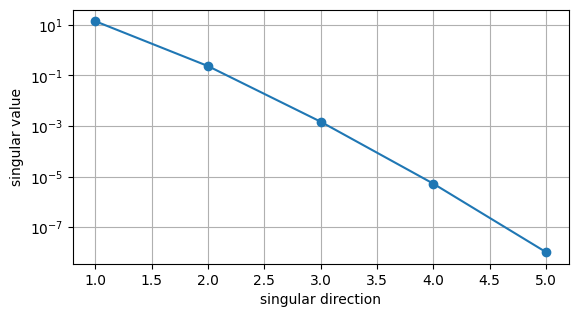

In [2]:
t = 1 + .02*np.linspace(-1, 1, 40)
A = np.vander(t, 5, increasing=True)
truth = np.array([1., -2, 3, -.5, .2]); y = A@truth
Q, R = np.linalg.qr(A, mode='reduced')
x_qr = np.linalg.solve(R, Q.T@y)
x_svd, _, rank, s = np.linalg.lstsq(A, y, rcond=None)
try:
    x_normal = np.linalg.solve(A.T@A, A.T@y)
    normal_error = np.linalg.norm(x_normal-truth)
except np.linalg.LinAlgError:
    normal_error = np.inf
print('condition number:', np.linalg.cond(A), 'rank:', rank)
print('parameter error, normal / QR / SVD:', normal_error,
      np.linalg.norm(x_qr-truth), np.linalg.norm(x_svd-truth))
plt.semilogy(np.arange(1, len(s)+1), s, 'o-')
plt.xlabel('singular direction'); plt.ylabel('singular value'); plt.show()

不同BLAS实现可能让上面最后几位不同；不要把某台机器上的具体误差比当成数学定理。应观察的是奇异值跨度、形成正规方程的危险，以及参数误差与残差大小的差别。

## 秩亏时，返回一个向量不等于参数唯一

当$A$两列完全相同，数据只能约束两参数的和。SVD可给出欧氏范数最小的解，但这只是选择一个表示的规则，不能凭空创造可辨识性。

In [3]:
A = np.ones((4, 2)); y = np.array([1., 2., 2., 3.])
x, residual_summary, rank, s = np.linalg.lstsq(A, y, rcond=None)
print('minimum-norm x:', x, 'rank:', rank, 'summary:', residual_summary)
print('explicit squared residual:', np.sum((A@x-y)**2))
assert np.allclose(x, [1, 1])
assert np.allclose(A@x, A@(x+np.array([5., -5.])))

minimum-norm x: [1. 1.] rank: 1 summary: []
explicit squared residual: 2.0


`lstsq`返回的`residuals`在秩亏或$m\le n$等条件下可能为空；空数组不表示误差为零，应直接计算$Ax-y$。这是一个容易在实际程序里误判的接口细节。

## 练习与解答

练习：将时间$t$中心化并缩放到$[-1,1]$，再构建多项式矩阵，比较条件数。解答：这常显著改善列的尺度和相关性，但它改变了系数的坐标表示；比较预测曲线比直接比较系数更合适。

练习：最小范数解是否一定最符合物理？解答：不一定，它依赖参数单位和坐标选择。物理先验应通过明确的约束或正则化表达，见第06章。